# Assignment 1: Data Profiling (EDA) Report

**Domain:** Logistics / Supply Chain  
**Dataset:** DataCo Smart Supply Chain  
**Group members:** SONG SHIHONG (A207394); LI HUA (A214086); CHU XINRAN (A214107)

## 1. Scenario

An e-commerce logistics organization needs to assess the reliability of order-item and shipping records before comparing shipping performance. This public dataset contains substantial missingness, unusual financial values, potential categorical inconsistencies, and sensitive customer information; therefore it is appropriate for diagnosing and documenting data quality problems. The goal is to determine which fields are fit for later shipping analysis, not to make business performance claims.

**Independence:** This dataset is not the group's capstone project dataset.

## 2. Data Source

- **Dataset:** DataCo Smart Supply Chain for Big Data Analysis
- **Kaggle:** https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis
- **Original source:** https://data.mendeley.com/datasets/8gx2fvg2k6/5
- **Acquisition:** Download `DataCoSupplyChainDataset.csv` from the public dataset and place it in the repository's local `data/` folder. The source CSV is not committed because it contains customer information.
- **Unit of observation:** An order-item record; one `Order Id` can legitimately appear on multiple rows.

**Scope:** Completeness, uniqueness, validity, type/format consistency, outlier screening, privacy minimization, and representation bias. No capstone data are used.

## 3. Initial Data Profiling

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
root = Path.cwd()
if not (root / "data").is_dir():
    root = root.parent
file_path = root / "data" / "DataCoSupplyChainDataset.csv"
if not file_path.is_file():
    raise FileNotFoundError(f"Download the source CSV and place it at: {file_path}")

df = pd.read_csv(file_path, encoding="latin1")
df.columns = df.columns.str.strip()
df_raw = df.copy(deep=True)
df_clean = df.copy(deep=True)
print(f"Rows: {len(df):,}; Columns: {df.shape[1]}")

Rows: 180,519; Columns: 53


In [22]:
# Profile types and numeric distributions without printing sensitive record values
display(df.dtypes.to_frame("Data Type"))
display(df.describe().T)
print("Column count:", len(df.columns))

,Data Type
Type,str
Days for shipping (real),int64
Days for shipment (scheduled),int64
Benefit per order,float64
Sales per customer,float64
Delivery Status,str
Late_delivery_risk,int64
Category Id,int64
Category Name,str
Customer City,str


,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


Column count: 53


In [23]:
# Preview non-sensitive columns
safe_columns = [
    "Order Id",
    "Order Item Id",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Shipping Mode",
    "Order Region"
]

display(df[safe_columns].head())

,Order Id,Order Item Id,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Shipping Mode,Order Region
0,77202,180517,3,4,Advance shipping,Standard Class,Southeast Asia
1,75939,179254,5,4,Late delivery,Standard Class,South Asia
2,75938,179253,4,4,Shipping on time,Standard Class,South Asia
3,75937,179252,3,4,Advance shipping,Standard Class,Oceania
4,75936,179251,2,4,Advance shipping,Standard Class,Oceania


## 4. Missing Values

In [24]:
missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing Count",
    ascending=False
)

display(
    missing_report[
        missing_report["Missing Count"] > 0
    ]
)

,Missing Count,Missing Percentage
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


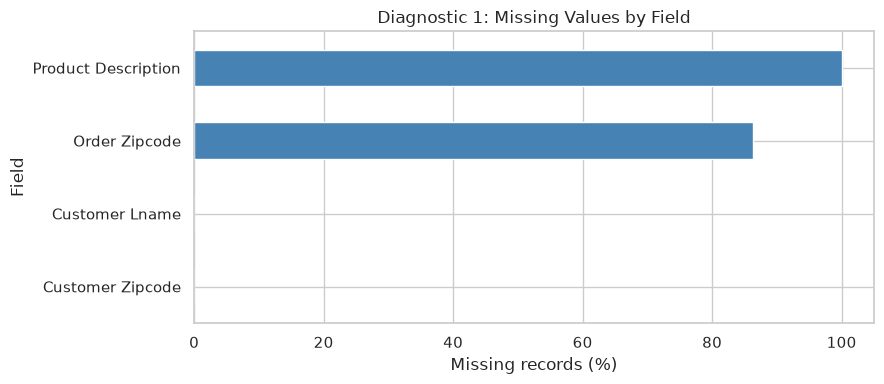

Interpretation: Product Description is entirely missing and Order Zipcode is mostly missing; neither supports reliable field-level analysis.


In [25]:
missing_plot = missing_report.loc[missing_report["Missing Count"] > 0].sort_values("Missing Percentage")
if not missing_plot.empty:
    ax = missing_plot["Missing Percentage"].plot(kind="barh", figsize=(9, 4), color="steelblue")
    ax.set_title("Diagnostic 1: Missing Values by Field")
    ax.set_xlabel("Missing records (%)")
    ax.set_ylabel("Field")
    plt.tight_layout()
    plt.show()
    print("Interpretation: Product Description is entirely missing and Order Zipcode is mostly missing; neither supports reliable field-level analysis.")

In [26]:
# Remove entirely missing columns
all_missing_cols = df_clean.columns[
    df_clean.isna().all()
].tolist()

df_clean = df_clean.drop(
    columns=all_missing_cols
)

print("Removed columns:", all_missing_cols)

# Remaining missing values
display(
    df_clean.isna().sum()[
        df_clean.isna().sum() > 0
    ]
)

Removed columns: ['Product Description']


Customer Lname           8
Customer Zipcode         3
Order Zipcode       155679
dtype: int64

Missing values were identified using `isna()` and summarized using counts and percentages.

The dataset contains 180,519 records and 53 columns. `Product Description` has 180,519 missing values (100%) and was removed because it provides no usable information.

`Order Zipcode` contains 155,679 missing values (86.24%), indicating poor completeness for detailed postal-code analysis. `Customer Lname` and `Customer Zipcode` contain 8 and 3 missing values, respectively.

These remaining fields were initially preserved for profiling and were subsequently excluded during PII minimization because they were not required for the selected logistics assessment. Missing values were not automatically replaced with zero, as inappropriate imputation could introduce misleading information.

The missing-value chart highlights the columns requiring attention and supports the documented decisions about which fields to exclude.

## 5. Outlier Detection

In [27]:
feature = "Benefit per order"

values = pd.to_numeric(
    df_clean[feature],
    errors="coerce"
).dropna()

Q1 = values.quantile(0.25)
Q3 = values.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (values < lower) | (values > upper)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Outliers:", outlier_mask.sum())
print("Outlier percentage:",
      round(outlier_mask.mean() * 100, 2))

Q1: 7.0
Q3: 64.80000305
IQR: 57.80000305
Lower bound: -79.70000457500001
Upper bound: 151.50000762500002
Outliers: 18942
Outlier percentage: 10.49


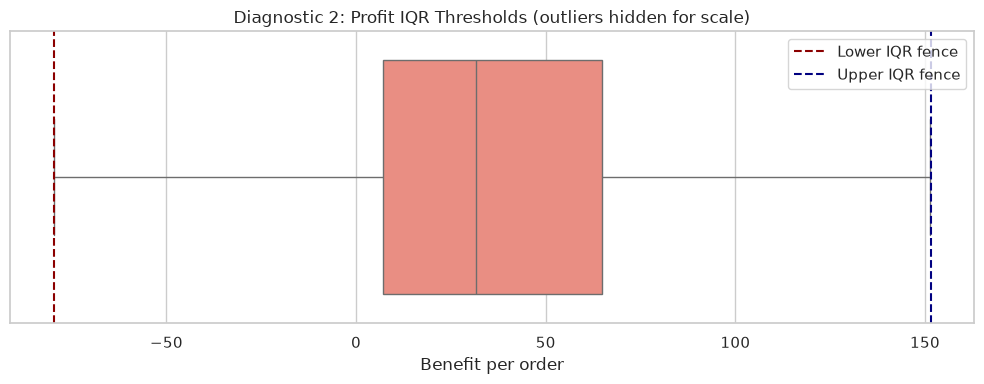

Interpretation: 18,942 (10.49%) records lie outside the IQR fences; flag them for verification rather than assuming errors.


In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=values, ax=ax, color="salmon", showfliers=False)
ax.axvline(lower, color="darkred", linestyle="--", label="Lower IQR fence")
ax.axvline(upper, color="navy", linestyle="--", label="Upper IQR fence")
ax.set_title("Diagnostic 2: Profit IQR Thresholds (outliers hidden for scale)")
ax.set_xlabel("Benefit per order")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Interpretation: {int(outlier_mask.sum()):,} ({outlier_mask.mean()*100:.2f}%) records lie outside the IQR fences; flag them for verification rather than assuming errors.")

In [29]:
df_clean["profit_outlier"] = (
    (df_clean["Benefit per order"] < lower)
    |
    (df_clean["Benefit per order"] > upper)
)

print(df_clean["profit_outlier"].value_counts())

profit_outlier
False    161577
True      18942
Name: count, dtype: int64


The Interquartile Range (IQR) method was applied to the `Benefit per order` feature to detect potential statistical outliers.

The first quartile (Q1) was approximately 7.00, while the third quartile (Q3) was approximately 64.80. The IQR was approximately 57.80, resulting in a lower boundary of -79.70 and an upper boundary of 151.50.

A total of 18,942 records (10.49%) were identified as potential outliers.

These observations were retained and flagged using the Boolean column `profit_outlier`, rather than automatically removed or capped. Unusually high profits or large losses may represent genuine business transactions, and removing them without verification could distort the original financial distribution.

Further business validation would be required to determine whether the flagged values represent errors or legitimate transactions.

## 6. Other Quality Issues

In [30]:
# Exact duplicate rows
duplicates = df_clean.duplicated().sum()

print("Exact duplicates:", duplicates)

# Repeated IDs
print(
    "Repeated Order IDs:",
    df_clean["Order Id"].duplicated().sum()
)

print(
    "Repeated Order Item IDs:",
    df_clean["Order Item Id"].duplicated().sum()
)

# Remove exact duplicates only
df_clean = df_clean.drop_duplicates().copy()

Exact duplicates: 0
Repeated Order IDs: 114767
Repeated Order Item IDs: 0


In [31]:
date_columns = [
    "order date (DateOrders)",
    "shipping date (DateOrders)"
]

for col in date_columns:
    print("\nBefore:", col)
    print("Data type:", df_clean[col].dtype)

    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="%m/%d/%Y %H:%M",
        errors="coerce"
    )

    print("After:", col)
    print("Data type:", df_clean[col].dtype)
    print("Invalid or missing dates:", df_clean[col].isna().sum())
    print(df_clean[col].head())



Before: order date (DateOrders)
Data type: str
After: order date (DateOrders)
Data type: datetime64[us]
Invalid or missing dates: 0
0   2018-01-31 22:56:00
1   2018-01-13 12:27:00
2   2018-01-13 12:06:00
3   2018-01-13 11:45:00
4   2018-01-13 11:24:00
Name: order date (DateOrders), dtype: datetime64[us]

Before: shipping date (DateOrders)
Data type: str
After: shipping date (DateOrders)
Data type: datetime64[us]
Invalid or missing dates: 0
0   2018-02-03 22:56:00
1   2018-01-18 12:27:00
2   2018-01-17 12:06:00
3   2018-01-16 11:45:00
4   2018-01-15 11:24:00
Name: shipping date (DateOrders), dtype: datetime64[us]


In [32]:
# Normalize whitespace; preserve established market acronyms (LATAM, USCA)
category_columns = ["Shipping Mode", "Delivery Status", "Order Region", "Market"]
for col in category_columns:
    before = df_clean[col].astype("string")
    normalized = before.str.strip().str.replace(r"\s+", " ", regex=True)
    if col != "Market":
        normalized = normalized.str.title()
    changed = int((before.fillna("<missing>") != normalized.fillna("<missing>")).sum())
    df_clean[col] = normalized
    print(f"{col}: {changed} values normalized")
print("Market categories:", df_clean["Market"].dropna().unique().tolist())

Shipping Mode: 0 values normalized
Delivery Status: 180519 values normalized
Order Region: 24840 values normalized
Market: 0 values normalized
Market categories: ['Pacific Asia', 'USCA', 'Africa', 'Europe', 'LATAM']


In [33]:
order_date = df_clean["order date (DateOrders)"]
shipping_date = df_clean["shipping date (DateOrders)"]

df_clean["invalid_date_format"] = (
    order_date.isna()
    |
    shipping_date.isna()
)

df_clean["invalid_date_sequence"] = (
    (shipping_date < order_date)
    &
    ~df_clean["invalid_date_format"]
)

print(
    "Invalid or missing date records:",
    df_clean["invalid_date_format"].sum()
)

print(
    "Invalid date sequences:",
    df_clean["invalid_date_sequence"].sum()
)

print("\nDate data types:")
print(df_clean[
    [
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ]
].dtypes)

display(
    df_clean.loc[
        df_clean["invalid_date_sequence"],
        [
            "Order Id",
            "order date (DateOrders)",
            "shipping date (DateOrders)"
        ]
    ].head(10)
)


Invalid or missing date records: 0
Invalid date sequences: 0

Date data types:
order date (DateOrders)       datetime64[us]
shipping date (DateOrders)    datetime64[us]
dtype: object


,Order Id,order date (DateOrders),shipping date (DateOrders)


In [34]:
# Additional numeric-domain validation (flag; do not silently delete)
numeric_columns = ["Days for shipping (real)", "Days for shipment (scheduled)", "Order Item Quantity"]
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
df_clean["invalid_shipping_days"] = (
    df_clean["Days for shipping (real)"].isna()
    | df_clean["Days for shipment (scheduled)"].isna()
    | (df_clean["Days for shipping (real)"] < 0)
    | (df_clean["Days for shipment (scheduled)"] < 0)
)
df_clean["invalid_quantity"] = (
    df_clean["Order Item Quantity"].isna()
    | (df_clean["Order Item Quantity"] <= 0)
)
print("Invalid shipping duration records:", int(df_clean["invalid_shipping_days"].sum()))
print("Invalid item quantities:", int(df_clean["invalid_quantity"].sum()))

Invalid shipping duration records: 0
Invalid item quantities: 0


**Uniqueness:** Exact duplicate rows are removed only if present. Repeated `Order Id` values are **not** automatically duplicates because the grain is order item; `Order Item Id` is checked separately.

**Dates:** Both date columns are parsed with an explicit format and `errors="coerce"`. Invalid/missing dates and shipping-before-order sequences are flagged separately. A shipment date is not necessarily a confirmed delivery date.

**Categories:** Whitespace is normalized, with consistent capitalization for descriptive labels. `Market` abbreviations are preserved to avoid changing established codes such as `LATAM` and `USCA`.

**Validity:** Missing/negative shipping durations and missing/non-positive quantities are flagged. Flagged records are retained for audit rather than silently deleted; any downstream calculation using these fields should filter or review the flags.

**Outliers:** IQR-based profit flags indicate unusual values, not proven errors. No unsupported winsorization or row deletion is performed.

## 7. Additional Diagnostic Chart: Validity Flags

This chart counts records requiring follow-up. It complements the missingness and profit-outlier charts and is intended to diagnose data quality, not describe sales performance.

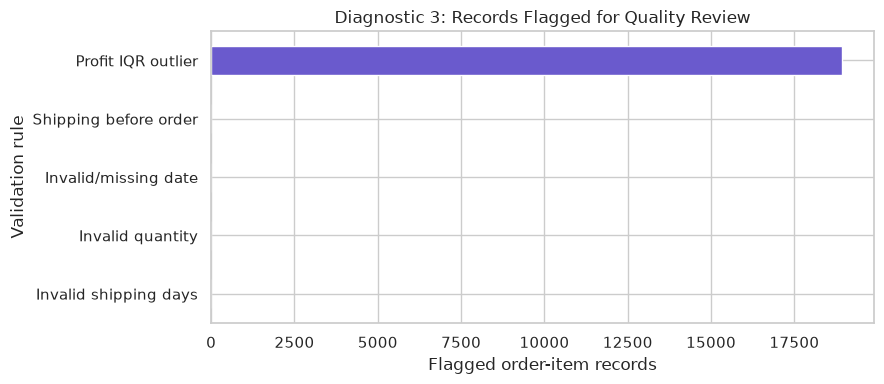

Interpretation: The plot distinguishes financial outlier flags from invalid shipping, quantity, and date records; flags can overlap.


In [35]:
flag_counts = pd.Series({
    "Profit IQR outlier": int(df_clean["profit_outlier"].sum()),
    "Invalid shipping days": int(df_clean["invalid_shipping_days"].sum()),
    "Invalid quantity": int(df_clean["invalid_quantity"].sum()),
    "Invalid/missing date": int(df_clean["invalid_date_format"].sum()),
    "Shipping before order": int(df_clean["invalid_date_sequence"].sum()),
})
ax = flag_counts.sort_values().plot(kind="barh", figsize=(9, 4), color="slateblue")
ax.set_title("Diagnostic 3: Records Flagged for Quality Review")
ax.set_xlabel("Flagged order-item records")
ax.set_ylabel("Validation rule")
plt.tight_layout()
plt.show()
print("Interpretation: The plot distinguishes financial outlier flags from invalid shipping, quantity, and date records; flags can overlap.")

## 8. PII and Bias Risks

In [36]:
pii_columns = [
    "Customer Fname",
    "Customer Lname",
    "Customer Email",
    "Customer Password",
    "Customer Street",
    "Customer Zipcode",
    "Customer Id",
    "Order Customer Id",
    "Order Zipcode",
    "Latitude",
    "Longitude"
]

existing_pii = [
    col for col in pii_columns
    if col in df_clean.columns
]

print("PII fields identified:")
print(existing_pii)

# Exclude unnecessary PII
df_clean = df_clean.drop(
    columns=existing_pii
)

PII fields identified:
['Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Street', 'Customer Zipcode', 'Customer Id', 'Order Customer Id', 'Order Zipcode', 'Latitude', 'Longitude']


In [37]:
region_report = pd.DataFrame({
    "Count": df_clean["Order Region"].value_counts(),
    "Percentage": (
        df_clean["Order Region"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(region_report)

,Count,Percentage
Order Region,,
Central America,28341,15.7
Western Europe,27109,15.02
South America,14935,8.27
Oceania,10148,5.62
Northern Europe,9792,5.42
Southeast Asia,9539,5.28
Southern Europe,9431,5.22
Caribbean,8318,4.61
West Of Usa,7993,4.43


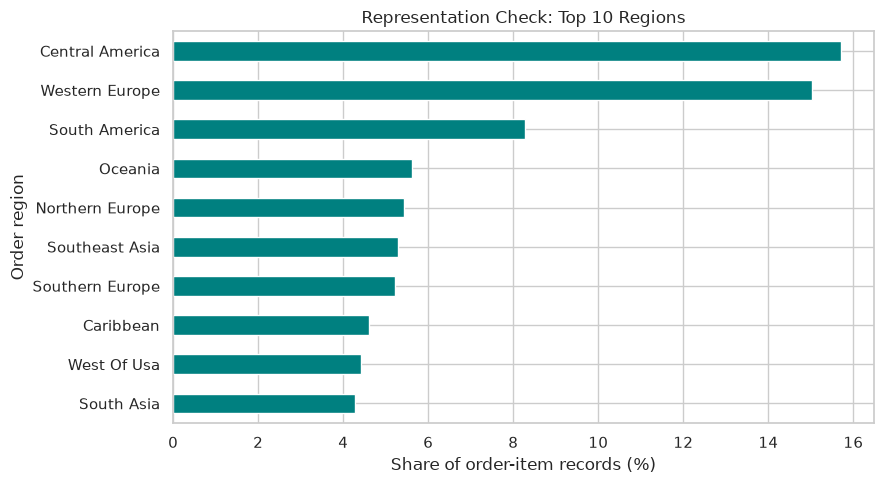

Interpretation: The largest region contributes 15.70% of rows; regional comparisons should use group-specific rates and disclose small groups.


In [38]:
region_counts = df_clean["Order Region"].value_counts()
region_pct = region_counts / region_counts.sum() * 100
ax = region_pct.head(10).sort_values().plot(kind="barh", figsize=(9, 5), color="teal")
ax.set_title("Representation Check: Top 10 Regions")
ax.set_xlabel("Share of order-item records (%)")
ax.set_ylabel("Order region")
plt.tight_layout()
plt.show()
print(f"Interpretation: The largest region contributes {region_pct.iloc[0]:.2f}% of rows; regional comparisons should use group-specific rates and disclose small groups.")

**Sensitive data and mitigation:** The original source includes names, email addresses, a password field, street/postal addresses, customer IDs, and precise coordinates. These fields are excluded from the cleaned export. Do not print sample customer records, publish the raw CSV, or commit credentials; the local CSV should remain Git-ignored. Removing these columns from the analytical output does **not** remove them from the original source file.

**Representation risks:** Order-item counts differ by region and shipping mode, and a large order may contribute multiple records. Overall metrics may overrepresent high-volume regions or multi-item orders. For later comparisons, report denominators, use within-group rates, consider order-level aggregation, and avoid strong claims about regions with small samples.

**Coverage limitation:** The source is an observational dataset with unknown sampling representativeness; the regional counts alone cannot establish real-world market shares.

## 9. Final Validation

In [39]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Cells",
        "Exact Duplicates"
    ],
    "Before": [
        len(df_raw),
        len(df_raw.columns),
        df_raw.isna().sum().sum(),
        df_raw.duplicated().sum()
    ],
    "After": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.isna().sum().sum(),
        df_clean.duplicated().sum()
    ]
})

display(quality_summary)

,Metric,Before,After
0,Rows,180519,180519
1,Columns,53,46
2,Missing Cells,336209,0
3,Exact Duplicates,0,0


**Interpretation of cleaning:** Missing-cell totals are not directly comparable when columns are removed. Most missing cells disappear because the entirely empty product-description field and unnecessary sensitive fields were excluded—not because missing customer data were reconstructed. Retained outliers and validation flags represent unresolved items for review, not errors that have been fixed. Original records are preserved unless exact duplicate rows exist.

In [40]:
# Recheck the cleaned dataset and show unresolved flags
required_flags = ["profit_outlier", "invalid_shipping_days", "invalid_quantity", "invalid_date_format", "invalid_date_sequence"]
missing_flags = [x for x in required_flags if x not in df_clean.columns]
if missing_flags:
    raise ValueError(f"Validation flags not created: {missing_flags}. Run all cells in order.")
remaining_issues = pd.Series({
    "Missing Cells": int(df_clean.isna().sum().sum()),
    "Exact Duplicates": int(df_clean.duplicated().sum()),
    "Profit Outliers (retained)": int(df_clean["profit_outlier"].sum()),
    "Invalid Shipping Records": int(df_clean["invalid_shipping_days"].sum()),
    "Invalid Quantities": int(df_clean["invalid_quantity"].sum()),
    "Invalid or Missing Dates": int(df_clean["invalid_date_format"].sum()),
    "Invalid Date Sequences": int(df_clean["invalid_date_sequence"].sum()),
})
display(remaining_issues.to_frame("Count"))
assert not set(existing_pii).intersection(df_clean.columns), "Sensitive fields remain in cleaned data"
print("PII exclusion check: passed")

,Count
Missing Cells,0
Exact Duplicates,0
Profit Outliers (retained),18942
Invalid Shipping Records,0
Invalid Quantities,0
Invalid or Missing Dates,0
Invalid Date Sequences,0


PII exclusion check: passed


In [41]:
# Save only the privacy-minimized analytical output locally (do not commit it)
output_path = root / "data" / "dataco_cleaned.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(output_path, index=False)
print("Cleaned local CSV saved:", output_path)
print("Keep data/*.csv in .gitignore; do not upload raw customer records to GitHub.")

Cleaned local CSV saved: /workspaces/Logistics-Supply-Chain-Data-Profiling/data/dataco_cleaned.csv
Keep data/*.csv in .gitignore; do not upload raw customer records to GitHub.


## 10. Conclusion: Fitness for Purpose and Limitations

The DataCo order-item dataset is **conditionally suitable** for exploratory assessment of shipping reliability, but not ready for unqualified operational conclusions. It has 180,519 original records and 53 fields; profiling exposed a completely missing product-description field, substantial missingness in order postal codes, and 18,942 IQR-based potential profit outliers (10.49%). Repeated order IDs are expected at the order-item grain and must not be removed as duplicates.

**Documented handling:** An entirely missing column was dropped; unnecessary sensitive fields were removed from the analytical export; date types and selected categorical formats were standardized; exact duplicates were checked; and profit, date, shipping-duration, and quantity issues were explicitly flagged for follow-up. Statistical outliers were retained because their validity cannot be established from distribution alone.

**Remaining limitations:** Column removal explains much of the reduction in missing-cell counts. Financial outliers remain unverified, group sizes differ, source representativeness is unknown, and shipping timestamps do not independently prove delivery completion. Future use should validate flagged source records, disclose denominators, and avoid exposing customer-level data.

**Reproducibility:** Download the cited source CSV into `data/`, install the packages listed in `requirements.txt`, and run the notebook from top to bottom. The cleaned local CSV is excluded from GitHub; no API keys are needed.